In [2]:
import sys
from pathlib import Path
# Make the repo root importable regardless of CWD or machine: walk up from the
# working dir until we hit a repo marker, then put that dir on sys.path.
_start = Path.cwd()
_root = next((p for p in (_start, *_start.parents)
              if (p / ".git").exists() or (p / "setup.py").exists()), _start)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

In [3]:
import os
import requests
import zipfile
import scanpy as sc
import pandas as pd
import glob, tarfile


In [4]:
from metab_processing.metab_travlr_config import PROJECT_DATA_DIR, DATA_DIR as METAB_DATA_DIR

ATERA_DATA_DIR = f'{METAB_DATA_DIR}/Atera'

In [5]:
def download_file(url, dest_dir, timeout=60):
    """Download url into dest_dir, resuming a partial file if present.
    
    Skips download entirely if the file is already fully downloaded.
    """
    os.makedirs(dest_dir, exist_ok=True)
    dest = os.path.join(dest_dir, os.path.basename(url))
    headers = {"User-Agent": "Mozilla/5.0"}
    
    # Check remote file size using a HEAD request
    try:
        with requests.head(url, headers=headers, timeout=timeout) as head_res:
            head_res.raise_for_status()
            remote_size = int(head_res.headers.get("Content-Length", 0))
    except requests.RequestException:
        # Fallback if HEAD request is blocked or unsupported by the server
        remote_size = None

    pos = os.path.getsize(dest) if os.path.exists(dest) else 0
    
    # Skip download if local size matches or exceeds remote size
    if remote_size and pos >= remote_size:
        print(f"File already fully downloaded: {dest}")
        return dest

    if pos:
        headers["Range"] = f"bytes={pos}-"
        
    with requests.get(url, headers=headers, stream=True, timeout=timeout) as r:
        # If server returns 416, it usually means we already have the full file
        if r.status_code == 416:
            print(f"File appears complete (Server returned 416). Skipping: {dest}")
            return dest
            
        r.raise_for_status()
        
        # If server doesn't support partial content (returns 200 instead of 206), reset position
        mode = "ab" if (pos and r.status_code == 206) else "wb"
        
        with open(dest, mode) as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                
    print("Saved to", dest)
    return dest


def unzip_file(zip_path, dest_dir):
    """Extract zip_path into dest_dir. Skips extraction if already unzipped."""
    os.makedirs(dest_dir, exist_ok=True)
    
    # Hidden marker file to guarantee complete extraction
    completion_marker = os.path.join(dest_dir, ".unzip_complete")
    
    if os.path.exists(completion_marker):
        print(f"Directory already extracted: {dest_dir}. Skipping unzip.")
        return dest_dir
        
    print(f"Extracting {zip_path} to {dest_dir}...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest_dir)
        
    # Create the marker file after successful extraction
    with open(completion_marker, "w") as f:
        f.write("extraction_complete")
        
    print("Extracted to", dest_dir)
    return dest_dir

def load_and_save_adata(raw, save_to_path=None, overwrite=False):
    """Loads Xenium h5 and parquet metadata into an AnnData object, with overwrite controls."""
    
    # If file exists and overwrite is False, read the saved object and skip processing
    if save_to_path and os.path.exists(save_to_path) and not overwrite:
        print(f"File already exists at {save_to_path}. Loading existing object (overwrite=False).")
        adata = sc.read_h5ad(save_to_path)
        print(adata)
        return adata

    # Otherwise, execute the parsing pipeline
    # expression matrix (cells × genes)
    adata = sc.read_10x_h5(os.path.join(raw, 'cell_feature_matrix.h5'))
    adata.var_names_make_unique()
    
    # cell metadata + coordinates, aligned on cell_id
    cells = pd.read_parquet(os.path.join(raw, 'cells.parquet')).set_index('cell_id')
    adata.obs = adata.obs.join(cells)
    adata.obsm['spatial'] = adata.obs[['x_centroid', 'y_centroid']].to_numpy()
    
    if save_to_path is not None:
        adata.write_h5ad(save_to_path)
        print(f"Saved AnnData object to {save_to_path}")
        
    print(adata)
    return adata

def untar_file(tar_path, dest_dir):
    """Extract tar_path into dest_dir. Skips if already extracted."""
    marker = os.path.join(dest_dir, f".untar_complete_{os.path.basename(tar_path)}")
    if os.path.exists(marker):
        print(f"Already extracted: {tar_path}. Skipping.")
        return dest_dir
    print(f"Extracting {tar_path} to {dest_dir}...")
    with tarfile.open(tar_path) as t:
        t.extractall(dest_dir)
    with open(marker, "w") as f:
        f.write("extraction_complete")
    return dest_dir
 
 
def _put(adata, slot, key, values, if_exists):
    """Write values into adata.obs or adata.obsm under key.
 
    if_exists: 'skip'      keep what's there
               'overwrite' replace it
               'rename'    write to f'{key}_10x' instead
    Returns the key written, or None if skipped.
    """
    store = adata.obs if slot == "obs" else adata.obsm
    if key in store:
        if if_exists == "skip":
            print(f"  {slot}['{key}'] already exists, skipping")
            return None
        if if_exists == "rename":
            key = f"{key}_10x"
        elif if_exists != "overwrite":
            raise ValueError("if_exists must be 'skip', 'overwrite' or 'rename'")
    store[key] = values
    print(f"  wrote {slot}['{key}']")
    return key
 
 
def _find(raw, pattern):
    hits = sorted(glob.glob(os.path.join(raw, pattern), recursive=True))
    return hits[0] if hits else None
 
 
def add_10x_annotations(adata, raw, cell_groups_csv=None, if_exists="skip", save_to_path=None):
    """Add 10x's PCA, UMAP, graph-based clusters and (optionally) cell-type labels.
 
    Works on an already-loaded adata; only re-saves if something was added.
    Writes: obsm['X_pca'], obsm['X_umap'], obs['graphclust'], obs['cell_type']
            (+ uns['cell_type_colors'] using 10x's colors).
    """
    tar_path = os.path.join(raw, "analysis.tar.gz")
    if os.path.exists(tar_path):
        untar_file(tar_path, raw)
 
    def read(path):  # 10x CSVs are keyed by cell barcode in the first column
        return pd.read_csv(path, index_col=0).reindex(adata.obs_names)
 
    changed = False
 
    # PCA and UMAP from analysis/
    for key, pattern in [("X_pca", "**/pca/*/projection.csv"),
                         ("X_umap", "**/umap/*/projection.csv")]:
        path = _find(raw, pattern)
        if path is None:
            print(f"No file found for {key}")
            continue
        print(f"{key} <- {os.path.relpath(path, raw)}")
        changed |= _put(adata, "obsm", key, read(path).to_numpy(), if_exists) is not None
 
    # Unsupervised graph-based clusters from analysis/
    path = _find(raw, "**/gene_expression_graphclust/clusters.csv")
    if path is None:
        print("No graphclust clusters found")
    else:
        print(f"graphclust <- {os.path.relpath(path, raw)}")
        s = read(path).iloc[:, 0].astype("Int64")
        cats = [str(c) for c in sorted(s.dropna().unique())]
        clusters = pd.Categorical(s.astype(str).where(s.notna()), categories=cats)
        changed |= _put(adata, "obs", "graphclust", clusters, if_exists) is not None
 
    # Curated cell types (separate supplemental CSV: cell_id, group, color)
    if cell_groups_csv:
        print(f"cell_type <- {os.path.basename(cell_groups_csv)}")
        g = pd.read_csv(cell_groups_csv, index_col="cell_id").reindex(adata.obs_names)
        labels = g["group"].astype("category")
        key = _put(adata, "obs", "cell_type", labels, if_exists)
        if key:
            color = g.dropna().groupby("group")["color"].first()
            adata.uns[f"{key}_colors"] = [color[c] for c in labels.cat.categories]
            print(f"  unlabeled cells: {labels.isna().sum():,}")
            changed = True
 
    if save_to_path and changed:
        adata.write_h5ad(save_to_path)
        print(f"Saved to {save_to_path}")
    elif save_to_path:
        print("Nothing new added; not re-saving.")
 
    print(adata)
    return adata

# FFPE Human Breast Cancer:
https://www.10xgenomics.com/datasets/atera-wta-ffpe-human-breast-cancer

File already fully downloaded: /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Breast_Cancer/WTA_Preview_FFPE_Breast_Cancer_outs.zip
Directory already extracted: /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Breast_Cancer/Raw_Data. Skipping unzip.
File already fully downloaded: /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Breast_Cancer/WTA_Preview_FFPE_Breast_Cancer_cell_groups.csv
File already exists at /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Breast_Cancer/adata.h5ad. Loading existing object (overwrite=False).
AnnData object with n_obs × n_vars = 170057 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method'
   

/tmp/ipykernel_615284/2584842063.py:105: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(dest_dir)


X_pca <- analysis/pca/gene_expression_10_components/projection.csv
  wrote obsm['X_pca']
X_umap <- analysis/umap/gene_expression_2_components/projection.csv
  wrote obsm['X_umap']
graphclust <- analysis/clustering/gene_expression_graphclust/clusters.csv
  wrote obs['graphclust']
cell_type <- WTA_Preview_FFPE_Breast_Cancer_cell_groups.csv
  wrote obs['cell_type']
  unlabeled cells: 12
Saved to /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Breast_Cancer/adata.h5ad
AnnData object with n_obs × n_vars = 170057 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'


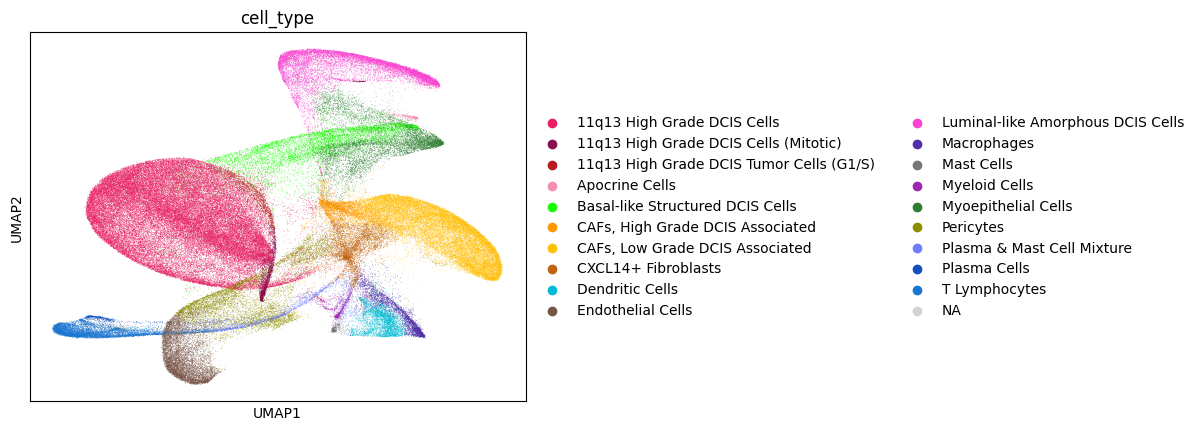

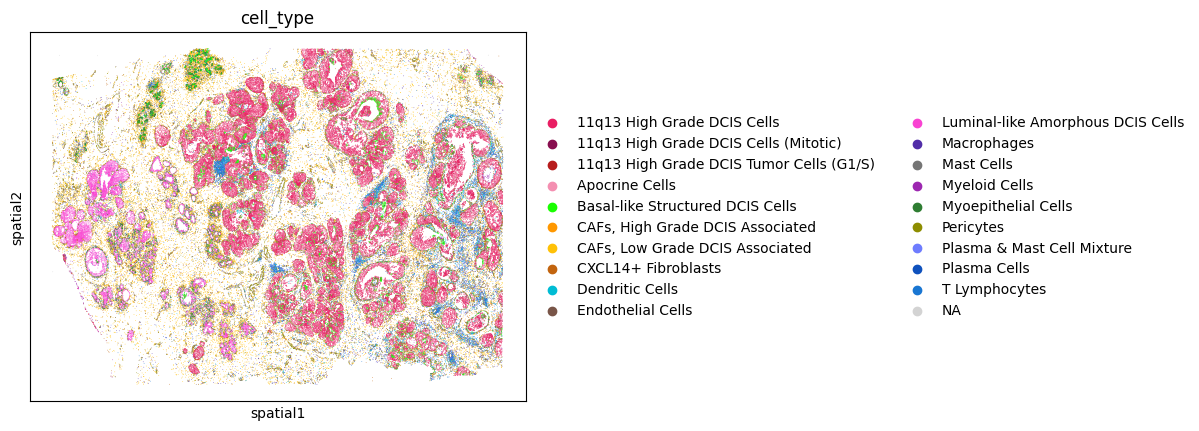

In [6]:
# Idempotent. Will not overwrite if already done.
data_set_name = 'FFPE_Human_Breast_Cancer'
this_dir = f'{ATERA_DATA_DIR}/{data_set_name}'
raw = f'{this_dir}/Raw_Data'
outs_url = "https://s3-us-west-2.amazonaws.com/10x.files/samples/atera/dev/WTA_Preview_FFPE_Breast_Cancer/WTA_Preview_FFPE_Breast_Cancer_outs.zip"
cell_groups_url = "https://s3-us-west-2.amazonaws.com/10x.files/samples/atera/dev/WTA_Preview_FFPE_Breast_Cancer/WTA_Preview_FFPE_Breast_Cancer_cell_groups.csv"

zip_path = download_file(outs_url, this_dir)
unzip_file(zip_path, raw)
cell_groups_csv = download_file(cell_groups_url, this_dir)   # already have it, so this skips

adata = load_and_save_adata(raw, f'{this_dir}/adata.h5ad', overwrite=False)
adata = add_10x_annotations(adata, raw, cell_groups_csv=cell_groups_csv,
                            if_exists='skip', save_to_path=f'{this_dir}/adata.h5ad')

sc.pl.umap(adata, color='cell_type')
sc.pl.embedding(adata, basis='spatial', color='cell_type', size=1)

In [8]:
adata[adata.obs['cell_type'] == 'T Lymphocytes']

View of AnnData object with n_obs × n_vars = 8018 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'

# FFPE Human Cervical Cancer:
https://www.10xgenomics.com/datasets/atera-wta-ffpe-human-cervical-cancer

File already fully downloaded: /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Cervical_Cancer/WTA_Preview_FFPE_Cervical_Cancer_outs.zip
Directory already extracted: /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Cervical_Cancer/Raw_Data. Skipping unzip.
Saved to /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Cervical_Cancer/WTA_Preview_FFPE_Cervical_Cancer_cell_groups.csv
File already exists at /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Cervical_Cancer/adata.h5ad. Loading existing object (overwrite=False).
AnnData object with n_obs × n_vars = 717576 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method'
    var: 'gen

/tmp/ipykernel_615284/2584842063.py:105: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(dest_dir)


X_pca <- analysis/pca/gene_expression_10_components/projection.csv
  wrote obsm['X_pca']
X_umap <- analysis/umap/gene_expression_2_components/projection.csv
  wrote obsm['X_umap']
graphclust <- analysis/clustering/gene_expression_graphclust/clusters.csv
  wrote obs['graphclust']
cell_type <- WTA_Preview_FFPE_Cervical_Cancer_cell_groups.csv
  wrote obs['cell_type']
  unlabeled cells: 293
Saved to /global/scratch/fsa/fc_wagnerlabfca/fosterangus/MetabTravLR/Data/Atera/FFPE_Human_Cervical_Cancer/adata.h5ad
AnnData object with n_obs × n_vars = 717576 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'


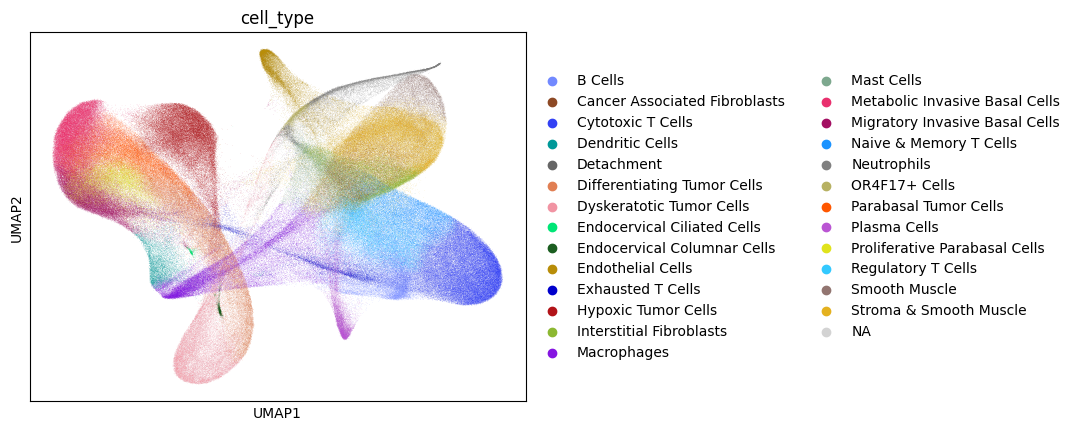

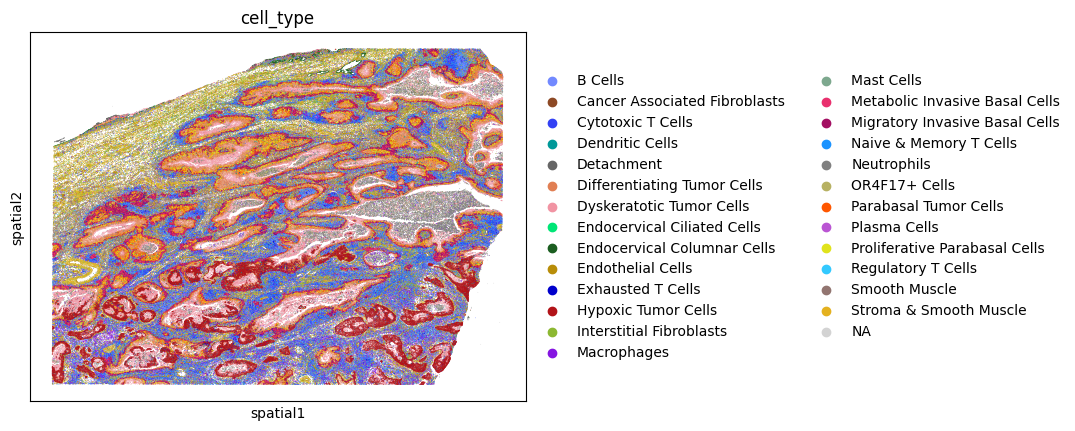

In [10]:
# Idempotent. Will not overwrite if already done.
data_set_name = 'FFPE_Human_Cervical_Cancer'
this_dir = f'{ATERA_DATA_DIR}/{data_set_name}'
raw = f'{this_dir}/Raw_Data'
outs_url = "https://s3-us-west-2.amazonaws.com/10x.files/samples/atera/dev/WTA_Preview_FFPE_Cervical_Cancer/WTA_Preview_FFPE_Cervical_Cancer_outs.zip"
cell_groups_url = "https://s3-us-west-2.amazonaws.com/10x.files/samples/atera/dev/WTA_Preview_FFPE_Cervical_Cancer/WTA_Preview_FFPE_Cervical_Cancer_cell_groups.csv"

zip_path = download_file(outs_url, this_dir)
unzip_file(zip_path, raw)
cell_groups_csv = download_file(cell_groups_url, this_dir)   # already have it, so this skips

adata = load_and_save_adata(raw, f'{this_dir}/adata.h5ad', overwrite=False)
adata = add_10x_annotations(adata, raw, cell_groups_csv=cell_groups_csv,
                            if_exists='skip', save_to_path=f'{this_dir}/adata.h5ad')

sc.pl.umap(adata, color='cell_type')
sc.pl.embedding(adata, basis='spatial', color='cell_type', size=1)

In [11]:
adata[adata.obs['cell_type'] == 'Naive & Memory T Cells']

View of AnnData object with n_obs × n_vars = 30504 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'

In [12]:
adata[adata.obs['cell_type'] == 'Regulatory T Cells']

View of AnnData object with n_obs × n_vars = 28967 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'

In [13]:
adata[adata.obs['cell_type'] == 'Cytotoxic T Cells']

View of AnnData object with n_obs × n_vars = 76154 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'

In [14]:
adata[adata.obs['cell_type'] == 'Exhausted T Cells']

View of AnnData object with n_obs × n_vars = 12320 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'